In [1]:
import pandas as pd
df=pd.read_csv("../data/solar data.csv")

In [2]:
df.head()

,Date,Time,DateTime,Country,DC_Power,AC_Power,Ambient_Temperature,Module_Temperature,Irradiation,Day,Month,Hour,Daily_Yield,Total_Yield
0,2024-01-01,0,2024-01-01 00:00:00,Norway,0.0,0.0,-10.15,-3.33,0.039,1,1,0,145.722,145.722
1,2024-01-01,1,2024-01-01 01:00:00,Norway,0.0,0.0,-10.06,-3.50,0.014,1,1,1,145.722,291.444
2,2024-01-01,2,2024-01-01 02:00:00,Norway,0.0,0.0,-9.95,-5.17,0.025,1,1,2,145.722,437.166
3,2024-01-01,3,2024-01-01 03:00:00,Norway,0.0,0.0,-9.27,-4.53,0.000,1,1,3,145.722,582.888
4,2024-01-01,4,2024-01-01 04:00:00,Norway,0.0,0.0,-9.62,-6.34,0.000,1,1,4,145.722,728.610


In [3]:
df.dtypes

Date                    object
Time                     int64
DateTime                object
Country                 object
DC_Power               float64
AC_Power               float64
Ambient_Temperature    float64
Module_Temperature     float64
Irradiation            float64
Day                      int64
Month                    int64
Hour                     int64
Daily_Yield            float64
Total_Yield            float64
dtype: object

In [4]:
df["Date"]=pd.to_datetime(df["Date"])
df["DateTime"]=pd.to_datetime(df["DateTime"])

In [5]:
df=df.sort_values(by="DateTime").reset_index(drop=True)

In [6]:
df.dtypes

Date                   datetime64[ns]
Time                            int64
DateTime               datetime64[ns]
Country                        object
DC_Power                      float64
AC_Power                      float64
Ambient_Temperature           float64
Module_Temperature            float64
Irradiation                   float64
Day                             int64
Month                           int64
Hour                            int64
Daily_Yield                   float64
Total_Yield                   float64
dtype: object

## Seperate X and y

In [7]:
X=df.drop(columns=["AC_Power","DC_Power","Date","Time","DateTime","Daily_Yield","Total_Yield"])
y=df["AC_Power"]

In [8]:
X.columns

Index(['Country', 'Ambient_Temperature', 'Module_Temperature', 'Irradiation',
       'Day', 'Month', 'Hour'],
      dtype='object')

## Train Test Split

In [9]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,shuffle=False)

In [10]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(28108, 7)
(7028, 7)
(28108,)
(7028,)


## Missing values

In [11]:
print("Missing values in training data\n",X_train.isnull().sum().sum())
print("Missing values in testing data\n",X_test.isnull().sum().sum())

Missing values in training data
 0
Missing values in testing data
 0


## Feature Engineering

#### Here we created a new feature named "Temperature_Difference" as it is the difference between the other two features module temperature and ambient temperature. 

In [12]:
X_train["Temperature_Difference"]=(X_train["Module_Temperature"]-X_train["Ambient_Temperature"])
X_test["Temperature_Difference"]=(X_test["Module_Temperature"]-X_test["Ambient_Temperature"])

In [13]:
X_train.head()

,Country,Ambient_Temperature,Module_Temperature,Irradiation,Day,Month,Hour,Temperature_Difference
0,Norway,-10.15,-3.33,0.039,1,1,0,6.82
1,Australia,8.32,14.89,0.015,1,1,0,6.57
2,Brazil,20.95,23.76,0.000,1,1,0,2.81
3,India,17.93,22.86,0.000,1,1,0,4.93
4,Norway,-10.06,-3.50,0.014,1,1,1,6.56


In [14]:
y_train.head()

0    0.0
1    0.0
2    0.0
3    0.0
4    0.0
Name: AC_Power, dtype: float64

In [15]:
print(X_train.shape)
print(y_train.shape)

(28108, 8)
(28108,)


## Numerical and Categorical columns

In [16]:
numerical_col=X_train.select_dtypes(include="number").columns
numerical_col

Index(['Ambient_Temperature', 'Module_Temperature', 'Irradiation', 'Day',
       'Month', 'Hour', 'Temperature_Difference'],
      dtype='object')

In [17]:
categorical_col=X_train.select_dtypes(include=["object","category"]).columns
categorical_col

Index(['Country'], dtype='object')

## Categorical Encoding

In [18]:
from sklearn.preprocessing import OneHotEncoder
encoder=OneHotEncoder(handle_unknown="ignore",sparse_output=False,dtype=int)
encoder

,categories,'auto'
,drop,None
,sparse_output,False
,dtype,<class 'int'>
,handle_unknown,'ignore'
,min_frequency,None
,max_categories,None
,feature_name_combiner,'concat'


#### Applying encoding to training data

In [19]:
encoded_train=encoder.fit_transform(X_train[categorical_col])
encoded_train

array([[0, 0, 0, 1],
       [1, 0, 0, 0],
       [0, 1, 0, 0],
       ...,
       [0, 1, 0, 0],
       [0, 0, 0, 1],
       [1, 0, 0, 0]], shape=(28108, 4))

#### Encoding testing data

In [20]:
encoded_test=encoder.transform(X_test[categorical_col])
encoded_test

array([[0, 1, 0, 0],
       [1, 0, 0, 0],
       [0, 0, 0, 1],
       ...,
       [0, 0, 0, 1],
       [0, 1, 0, 0],
       [1, 0, 0, 0]], shape=(7028, 4))

#### Convert encoded arrays to DataFrames

In [21]:
encoded_train_df=pd.DataFrame(encoded_train,columns=encoder.get_feature_names_out(categorical_col),index=X_train.index)
encoded_train_df

,Country_Australia,Country_Brazil,Country_India,Country_Norway
0,0,0,0,1
1,1,0,0,0
2,0,1,0,0
3,0,0,1,0
4,0,0,0,1
...,...,...,...,...
28103,1,0,0,0
28104,0,0,1,0
28105,0,1,0,0
28106,0,0,0,1


In [22]:
encoded_test_df=pd.DataFrame(encoded_test,columns=encoder.get_feature_names_out(categorical_col),index=X_test.index)
encoded_test_df

,Country_Australia,Country_Brazil,Country_India,Country_Norway
28108,0,1,0,0
28109,1,0,0,0
28110,0,0,0,1
28111,0,0,1,0
28112,0,0,1,0
...,...,...,...,...
35131,1,0,0,0
35132,0,0,1,0
35133,0,0,0,1
35134,0,1,0,0


In [23]:
X_train_num=X_train[numerical_col].copy()
X_test_num=X_test[numerical_col].copy()

In [24]:
X_train_final = pd.concat([X_train_num, encoded_train_df],axis=1)
X_test_final = pd.concat([X_test_num, encoded_test_df],axis=1)
print("Training shape:",X_train_final.shape)
print("Testing shape:",X_test_final.shape)
print("Training missing values:",X_train_final.isnull().sum().sum())
print("Testing missing values:",X_test_final.isnull().sum().sum())

Training shape: (28108, 11)
Testing shape: (7028, 11)
Training missing values: 0
Testing missing values: 0


## Feature Scaling

In [25]:
from sklearn.preprocessing import StandardScaler
numerical_features=X_train.select_dtypes(include="number").columns
scaler=StandardScaler()

In [26]:
sca_train=scaler.fit_transform(X_train[numerical_features])
sca_train

array([[-2.94303208, -2.76580648, -0.74713771, ..., -1.55690068,
        -1.66089585,  1.62129289],
       [-1.23708576, -1.08859926, -0.81353658, ..., -1.55690068,
        -1.66089585,  1.39833631],
       [-0.0705399 , -0.27208839, -0.85503588, ..., -1.55690068,
        -1.66089585, -1.95493075],
       ...,
       [ 0.05137939,  0.20750818, -0.38471053, ...,  1.68084454,
         0.94029618,  1.51427373],
       [-2.21151639, -2.17758726, -0.85503588, ...,  1.68084454,
         0.94029618,  0.25679858],
       [-0.72908875, -0.70657896, -0.30724518, ...,  1.68084454,
         0.94029618,  0.19437074]], shape=(28108, 7))

In [27]:
sca_test=scaler.transform(X_test[numerical_features])
sca_test

array([[ 1.04026348e-01,  3.44483815e-02, -8.13536583e-01, ...,
         1.68084454e+00,  1.08480685e+00, -6.70700814e-01],
       [-7.11539761e-01, -7.09340549e-01, -8.46736019e-01, ...,
         1.68084454e+00,  1.08480685e+00, -1.83105516e-03],
       [-2.22629448e+00, -2.36169343e+00, -8.55035878e-01, ...,
         1.68084454e+00,  1.08480685e+00, -1.38416189e+00],
       ...,
       [-2.89962143e+00, -2.92321726e+00, -8.02470104e-01, ...,
         2.40034348e+00,  1.66284953e+00, -3.22888539e-01],
       [-1.08408765e-01, -2.90682474e-02, -8.27369681e-01, ...,
         2.40034348e+00,  1.66284953e+00,  7.65139602e-01],
       [-1.25186385e+00, -1.26718225e+00, -8.55035878e-01, ...,
         2.40034348e+00,  1.66284953e+00, -1.89114588e-01]],
      shape=(7028, 7))

In [28]:
sca_train_df=pd.DataFrame(sca_train,columns=numerical_features,index=X_train.index)
sca_test_df=pd.DataFrame(sca_test,columns=numerical_features,index=X_test.index)

In [29]:
X_train_processed=pd.concat([sca_train_df, encoded_train_df], axis=1)
X_test_processed=pd.concat([sca_test_df, encoded_test_df], axis=1)
print("Training shape:",X_train_processed.shape)
print("Testing shape:",X_test_processed.shape)
print("Training missing values:",X_train_processed.isnull().sum().sum())
print("Testing missing values:",X_test_processed.isnull().sum().sum())
print("Same columns:",X_train_processed.columns.equals(X_test_processed.columns))

Training shape: (28108, 11)
Testing shape: (7028, 11)
Training missing values: 0
Testing missing values: 0
Same columns: True


## Baseline model

In [30]:
baseline_prediction=[y_train.mean()]*len(y_test)
baseline_prediction

[np.float64(16.805757079834923),
 np.float64(16.805757079834923),
 np.float64(16.805757079834923),
 np.float64(16.805757079834923),
 np.float64(16.805757079834923),
 np.float64(16.805757079834923),
 np.float64(16.805757079834923),
 np.float64(16.805757079834923),
 np.float64(16.805757079834923),
 np.float64(16.805757079834923),
 np.float64(16.805757079834923),
 np.float64(16.805757079834923),
 np.float64(16.805757079834923),
 np.float64(16.805757079834923),
 np.float64(16.805757079834923),
 np.float64(16.805757079834923),
 np.float64(16.805757079834923),
 np.float64(16.805757079834923),
 np.float64(16.805757079834923),
 np.float64(16.805757079834923),
 np.float64(16.805757079834923),
 np.float64(16.805757079834923),
 np.float64(16.805757079834923),
 np.float64(16.805757079834923),
 np.float64(16.805757079834923),
 np.float64(16.805757079834923),
 np.float64(16.805757079834923),
 np.float64(16.805757079834923),
 np.float64(16.805757079834923),
 np.float64(16.805757079834923),
 np.float6

##### The baseline is a reference point.Our regression models should perform better than this simple average prediction.

In [31]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
import numpy as np
print("MAE: ",mean_absolute_error(y_test,baseline_prediction))
print("MSE: ",mean_squared_error(y_test,baseline_prediction))
print("RMSE: ",np.sqrt(mean_squared_error(y_test,baseline_prediction)))
print("R2 Score: ",r2_score(y_test,baseline_prediction))

MAE:  18.024975900115816
MSE:  424.4116041464824
RMSE:  20.601252489751257
R2 Score:  -0.0025609417661061062


## Model Building

### Linear Regression

In [32]:
from sklearn.linear_model import LinearRegression

In [33]:
linear_model=LinearRegression()

In [34]:
linear_model.fit(X_train_processed,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [35]:
y_pred_linear=linear_model.predict(X_test_processed)
y_pred_linear

array([ 3.34932537,  1.00201712, -3.15606739, ..., -1.68435424,
        3.21086382,  1.18201887], shape=(7028,))

In [36]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
import numpy as np
print("MAE: ",mean_absolute_error(y_test,y_pred_linear))
print("MSE: ",mean_squared_error(y_test,y_pred_linear))
print("RMSE: ",np.sqrt(mean_squared_error(y_test,y_pred_linear)))
print("R2 Score: ",r2_score(y_test,y_pred_linear))

MAE:  2.044676331713731
MSE:  7.064760443560713
RMSE:  2.65796170844516
R2 Score:  0.9833113590334265


#### Check for Overfitting

In [37]:
y_train_pred_linear=linear_model.predict(X_train_processed)
print("Training R2:", r2_score(y_train, y_train_pred_linear))
print("Testing R2:", r2_score(y_test, y_pred_linear))

Training R2: 0.9812073445203122
Testing R2: 0.9833113590334265


##### Linear Regression performed  better than the baseline model.

### Decision Tree Regressor

In [38]:
from sklearn.tree import DecisionTreeRegressor

In [39]:
decision_tree_model=DecisionTreeRegressor(max_depth=10,random_state=42)
decision_tree_model

,criterion,'squared_error'
,splitter,'best'
,max_depth,10
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [40]:
decision_tree_model.fit(X_train_processed,y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,10
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [41]:
y_pred_tree=decision_tree_model.predict(X_test_processed)
y_pred_tree

array([0., 0., 0., ..., 0., 0., 0.], shape=(7028,))

In [42]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
import numpy as np
print("MAE: ",mean_absolute_error(y_test,y_pred_tree))
print("MSE: ",mean_squared_error(y_test,y_pred_tree))
print("RMSE: ",np.sqrt(mean_squared_error(y_test,y_pred_tree)))
print("R2 Score: ",r2_score(y_test,y_pred_tree))

MAE:  0.6697053656857694
MSE:  1.6718900654893416
RMSE:  1.2930158798287597
R2 Score:  0.9960505988474154


In [43]:
y_train_pred_tree=decision_tree_model.predict(X_train_processed)
print("Training R2:", r2_score(y_train, y_train_pred_tree))
print("Testing R2:", r2_score(y_test, y_pred_tree))

Training R2: 0.9978111391709469
Testing R2: 0.9960505988474154


####  Decision Tree model achieved lower prediction errors and a higher R² score

### Random Forest Regressor

In [44]:
from sklearn.ensemble import RandomForestRegressor

In [45]:
random_forest_model=RandomForestRegressor(random_state=42)
random_forest_model

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [46]:
random_forest_model.fit(X_train_processed,y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [47]:
y_pred_forest=random_forest_model.predict(X_test_processed)
y_pred_forest

array([0., 0., 0., ..., 0., 0., 0.], shape=(7028,))

In [48]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
import numpy as np
print("MAE: ",mean_absolute_error(y_test,y_pred_forest))
print("MSE: ",mean_squared_error(y_test,y_pred_forest))
print("RMSE: ",np.sqrt(mean_squared_error(y_test,y_pred_forest)))
print("R2 Score: ",r2_score(y_test,y_pred_forest))

MAE:  0.5962122239612977
MSE:  1.286755089241676
RMSE:  1.1343522773996075
R2 Score:  0.9969603790718993


In [49]:
y_train_pred_forest = random_forest_model.predict(X_train_processed)
print("Training R2:", r2_score(y_train, y_train_pred_forest))
print("Testing R2:", r2_score(y_test, y_pred_forest))

Training R2: 0.9995929012375223
Testing R2: 0.9969603790718993


#### Random Forest is the best-performing model among the three algorithms evaluated so far.

### Gradient Boosting Regressor

In [50]:
from sklearn.ensemble import GradientBoostingRegressor

In [51]:
gradient_boosting_model=GradientBoostingRegressor(random_state=42)
gradient_boosting_model

,loss,'squared_error'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [52]:
gradient_boosting_model.fit(X_train_processed,y_train)

,loss,'squared_error'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [53]:
y_pred_gradboost=gradient_boosting_model.predict(X_test_processed)
y_pred_gradboost

array([ 0.04763496,  0.06312206, -0.10780727, ..., -0.10486066,
        0.05058157,  0.06312206], shape=(7028,))

In [54]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
import numpy as np
print("MAE: ",mean_absolute_error(y_test,y_pred_gradboost))
print("MSE: ",mean_squared_error(y_test,y_pred_gradboost))
print("RMSE: ",np.sqrt(mean_squared_error(y_test,y_pred_gradboost)))
print("R2 Score: ",r2_score(y_test,y_pred_gradboost))

MAE:  0.6355600155860964
MSE:  1.2507985516964326
RMSE:  1.118391054907197
R2 Score:  0.9970453169477532


In [55]:
y_train_pred_gb = gradient_boosting_model.predict(X_train_processed)
print("Training R2:", r2_score(y_train, y_train_pred_gb))
print("Testing R2:", r2_score(y_test, y_pred_gradboost))

Training R2: 0.9970453729691222
Testing R2: 0.9970453169477532


#### Gradient Boosting achieved the lowest RMSE and highest R² score, while Random Forest achieved the lowest MAE.

#### Both Random Forest and Gradient Boosting are strong-performing models and will be considered for further evaluation and hyperparameter tuning.

### Voting Regressor

In [56]:
from sklearn.ensemble import VotingRegressor

In [57]:
voting_model=VotingRegressor(estimators=[
("Linear Regression",linear_model),
("Decision tree",decision_tree_model),
("Random Forest",random_forest_model),
("Gradient Boosting",gradient_boosting_model)   
]
)
voting_model

,estimators,"[('Linear Regression', ...), ('Decision tree', ...), ...]"
,weights,None
,n_jobs,None
,verbose,False
,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False
,criterion,'squared_error'
,splitter,'best'


In [58]:
voting_model.fit(X_train_processed,y_train)

,estimators,"[('Linear Regression', ...), ('Decision tree', ...), ...]"
,weights,None
,n_jobs,None
,verbose,False
,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False
,criterion,'squared_error'
,splitter,'best'


In [59]:
y_pred_voting=voting_model.predict(X_test_processed)
y_pred_voting

array([ 0.84924008,  0.2662848 , -0.81596866, ..., -0.44730372,
        0.81536135,  0.31128523], shape=(7028,))

In [60]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
import numpy as np
print("MAE: ",mean_absolute_error(y_test,y_pred_voting))
print("MSE: ",mean_squared_error(y_test,y_pred_voting))
print("RMSE: ",np.sqrt(mean_squared_error(y_test,y_pred_voting)))
print("R2 Score: ",r2_score(y_test,y_pred_voting))

MAE:  0.8845640176626985
MSE:  1.582589499686735
RMSE:  1.2580101349698003
R2 Score:  0.9962615479790523


In [61]:
y_train_pred_voting=voting_model.predict(X_train_processed)
print("Training R2:",r2_score(y_train, y_train_pred_voting))
print("Testing R2:",r2_score(y_test, y_pred_voting))

Training R2: 0.9972323504086222
Testing R2: 0.9962615479790523


#### Model Comparison

In [62]:
model_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting",
        "Voting Regressor"
    ],

    "MAE": [
        mean_absolute_error(y_test, y_pred_linear),
        mean_absolute_error(y_test, y_pred_tree),
        mean_absolute_error(y_test, y_pred_forest),
        mean_absolute_error(y_test, y_pred_gradboost),
        mean_absolute_error(y_test, y_pred_voting)
    ],

    "MSE": [
        mean_squared_error(y_test, y_pred_linear),
        mean_squared_error(y_test, y_pred_tree),
        mean_squared_error(y_test, y_pred_forest),
        mean_squared_error(y_test, y_pred_gradboost),
        mean_squared_error(y_test, y_pred_voting)
    ],

    "RMSE": [
        np.sqrt(mean_squared_error(y_test, y_pred_linear)),
        np.sqrt(mean_squared_error(y_test, y_pred_tree)),
        np.sqrt(mean_squared_error(y_test, y_pred_forest)),
        np.sqrt(mean_squared_error(y_test, y_pred_gradboost)),
        np.sqrt(mean_squared_error(y_test, y_pred_voting))
    ],

    "R2 Score": [
        r2_score(y_test, y_pred_linear),
        r2_score(y_test, y_pred_tree),
        r2_score(y_test, y_pred_forest),
        r2_score(y_test, y_pred_gradboost),
        r2_score(y_test, y_pred_voting)
    ]
})

model_results

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,2.044676,7.064760,2.657962,0.983311
1,Decision Tree,0.669705,1.671890,1.293016,0.996051
2,Random Forest,0.596212,1.286755,1.134352,0.996960
3,Gradient Boosting,0.635560,1.250799,1.118391,0.997045
4,Voting Regressor,0.884564,1.582589,1.258010,0.996262


####
Gradient Boosting: Best RMSE and R².



Random Forest: Best MAE.



Voting Regressor: Performs worse than both Gradient Boosting and Random Forest.



Linear Regression: Has the largest prediction errors.

## Cross Validation

In [63]:
from sklearn.model_selection import cross_val_score,TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer

In [64]:
preprocessor = make_column_transformer(
    (StandardScaler(), X_train.select_dtypes(include="number").columns),
    (OneHotEncoder(handle_unknown="ignore"),
     X_train.select_dtypes(include=["object", "category"]).columns)
)

In [65]:
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42)
}

models["Voting Regressor"] = VotingRegressor([
    ("lr", LinearRegression()),
    ("dt", DecisionTreeRegressor(random_state=42)),
    ("rf", RandomForestRegressor(random_state=42)),
    ("gb", GradientBoostingRegressor(random_state=42))
])

In [66]:
tscv=TimeSeriesSplit(n_splits=5)
results={}
for name, algorithm in models.items():
    model=make_pipeline(preprocessor, algorithm)
    results[name]=cross_val_score(model, X_train, y_train, cv=tscv, scoring="r2").mean()
cv_table=pd.DataFrame(results.items(), columns=["Model", "Mean CV R2"])
cv_table=cv_table.sort_values("Mean CV R2", ascending=False).reset_index(drop=True)
cv_table

,Model,Mean CV R2
0,Gradient Boosting,0.995803
1,Random Forest,0.995118
2,Voting Regressor,0.994330
3,Decision Tree,0.990291
4,Linear Regression,0.980341


### 
TimeSeriesSplit with 5 splits was used to evaluate the regression models.
Gradient Boosting achieved the highest mean CV R² score of 0.9958, followed by Random Forest with 0.9951. Therefore, Gradient Boosting was selected for hyperparameter tuning.

## Hyperparameter Tuning

#### Hyperparameter Tuning for Random Forest

In [67]:
from sklearn.model_selection import GridSearchCV

In [68]:
rf_pipeline=make_pipeline(preprocessor,RandomForestRegressor(random_state=42))

In [69]:
param_grid={"randomforestregressor__n_estimators":[100,200],"randomforestregressor__max_depth":[10,20,None],"randomforestregressor__min_samples_split":[2,5]}
param_grid

{'randomforestregressor__n_estimators': [100, 200],
 'randomforestregressor__max_depth': [10, 20, None],
 'randomforestregressor__min_samples_split': [2, 5]}

In [70]:
grid_search=GridSearchCV(rf_pipeline,param_grid,cv=TimeSeriesSplit(n_splits=5),scoring="r2",n_jobs=-1)
grid_search

,estimator,Pipeline(step...m_state=42))])
,param_grid,"{'randomforestregressor__max_depth': [10, 20, ...], 'randomforestregressor__min_samples_split': [2, 5], 'randomforestregressor__n_estimators': [100, 200]}"
,scoring,'r2'
,n_jobs,-1
,refit,True
,cv,TimeSeriesSpl...est_size=None)
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('standardscaler', ...), ('onehotencoder', ...)]"


In [71]:
grid_search.fit(X_train,y_train)

,estimator,Pipeline(step...m_state=42))])
,param_grid,"{'randomforestregressor__max_depth': [10, 20, ...], 'randomforestregressor__min_samples_split': [2, 5], 'randomforestregressor__n_estimators': [100, 200]}"
,scoring,'r2'
,n_jobs,-1
,refit,True
,cv,TimeSeriesSpl...est_size=None)
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('standardscaler', ...), ('onehotencoder', ...)]"


In [72]:
grid_search.best_params_

{'randomforestregressor__max_depth': 10,
 'randomforestregressor__min_samples_split': 5,
 'randomforestregressor__n_estimators': 100}

In [73]:
grid_search.best_score_

np.float64(0.995207063247751)

In [74]:
best_rf_model=grid_search.best_estimator_
best_rf_model

,steps,"[('columntransformer', ...), ('randomforestregressor', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('standardscaler', ...), ('onehotencoder', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [75]:
y_pred_tuned_rf=best_rf_model.predict(X_test)
y_pred_tuned_rf

array([0., 0., 0., ..., 0., 0., 0.], shape=(7028,))

In [76]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
mae_tuned=mean_absolute_error(y_test, y_pred_tuned_rf)
mse_tuned=mean_squared_error(y_test, y_pred_tuned_rf)
rmse_tuned=np.sqrt(mse_tuned)
r2_tuned=r2_score(y_test, y_pred_tuned_rf)
print("MAE:",mae_tuned)
print("MSE:",mse_tuned)
print("RMSE:",rmse_tuned)
print("R2 Score:",r2_tuned)

MAE: 0.5791195098557701
MSE: 1.218049474711626
RMSE: 1.1036527872078365
R2 Score: 0.9971226780404828


#### Hyperparameter Tuning for Gradient Boosting

In [77]:
gb_pipeline=make_pipeline(preprocessor,GradientBoostingRegressor(random_state=42))

In [78]:
param_grid_gb={"gradientboostingregressor__n_estimators":[100,200],"gradientboostingregressor__learning_rate":[0.05,0.1],"gradientboostingregressor__max_depth":[2,3,4]}

In [79]:
grid_search_gb=GridSearchCV(gb_pipeline,param_grid_gb,cv=TimeSeriesSplit(n_splits=5),scoring="r2",n_jobs=-1)
grid_search_gb

,estimator,Pipeline(step...m_state=42))])
,param_grid,"{'gradientboostingregressor__learning_rate': [0.05, 0.1], 'gradientboostingregressor__max_depth': [2, 3, ...], 'gradientboostingregressor__n_estimators': [100, 200]}"
,scoring,'r2'
,n_jobs,-1
,refit,True
,cv,TimeSeriesSpl...est_size=None)
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('standardscaler', ...), ('onehotencoder', ...)]"


In [80]:
grid_search_gb.fit(X_train,y_train)

,estimator,Pipeline(step...m_state=42))])
,param_grid,"{'gradientboostingregressor__learning_rate': [0.05, 0.1], 'gradientboostingregressor__max_depth': [2, 3, ...], 'gradientboostingregressor__n_estimators': [100, 200]}"
,scoring,'r2'
,n_jobs,-1
,refit,True
,cv,TimeSeriesSpl...est_size=None)
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('standardscaler', ...), ('onehotencoder', ...)]"


In [81]:
grid_search_gb.best_params_

{'gradientboostingregressor__learning_rate': 0.05,
 'gradientboostingregressor__max_depth': 4,
 'gradientboostingregressor__n_estimators': 200}

In [82]:
grid_search_gb.best_score_

np.float64(0.99622130158373)

In [83]:
best_gb_model=grid_search_gb.best_estimator_
best_gb_model

,steps,"[('columntransformer', ...), ('gradientboostingregressor', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('standardscaler', ...), ('onehotencoder', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [84]:
y_pred_tuned_gb=best_gb_model.predict(X_test)
y_pred_tuned_gb

array([ 0.01579303,  0.04517045, -0.01876125, ..., -0.01205064,
        0.03979213,  0.03338536], shape=(7028,))

In [85]:
mae_gb=mean_absolute_error(y_test, y_pred_tuned_gb)
mse_gb=mean_squared_error(y_test, y_pred_tuned_gb)
rmse_gb=np.sqrt(mse_gb)
r2_gb=r2_score(y_test, y_pred_tuned_gb)
print("MAE:",mae_gb)
print("MSE:",mse_gb)
print("RMSE:",rmse_gb)
print("R2 Score:",r2_gb)

MAE: 0.6000249598299742
MSE: 1.2068853594147857
RMSE: 1.0985833420431905
R2 Score: 0.9971490503305819


In [86]:
tuned_results = pd.DataFrame({
    "Model": ["Tuned Random Forest", "Tuned Gradient Boosting"],
    "MAE": [mae_tuned,mae_gb],
    "MSE": [mse_tuned,mse_gb],
    "RMSE": [rmse_tuned,rmse_gb],
    "R2 Score": [r2_tuned,r2_gb]})
final_model_comparison = pd.concat([model_results, tuned_results],ignore_index=True)
final_model_comparison

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,2.044676,7.064760,2.657962,0.983311
1,Decision Tree,0.669705,1.671890,1.293016,0.996051
2,Random Forest,0.596212,1.286755,1.134352,0.996960
3,Gradient Boosting,0.635560,1.250799,1.118391,0.997045
4,Voting Regressor,0.884564,1.582589,1.258010,0.996262
5,Tuned Random Forest,0.579120,1.218049,1.103653,0.997123
6,Tuned Gradient Boosting,0.600025,1.206885,1.098583,0.997149


##### After comparing all seven regression models, Tuned Gradient Boosting was selected as the final model.
##### It achieved the lowest RMSE of 1.0986 and the highest R² score of 0.9971 on the test dataset.
##### Although Tuned Random Forest achieved a slightly lower MAE, Gradient Boosting showed better overall performance based on RMSE, MSE and R².

## Feature Analysis

In [87]:
importance_df=pd.DataFrame({
    "Feature":X_train_processed.columns,
    "Importance":best_gb_model.named_steps["gradientboostingregressor"].feature_importances_})
importance_df

,Feature,Importance
0,Ambient_Temperature,0.000024
1,Module_Temperature,0.000020
2,Irradiation,0.973040
3,Day,0.000008
4,Month,0.000009
5,Hour,0.000077
6,Temperature_Difference,0.000013
7,Country_Australia,0.000831
8,Country_Brazil,0.009156
9,Country_India,0.000420


####  Irradiation is the most influential feature

## Actual vs Predicted Analysis

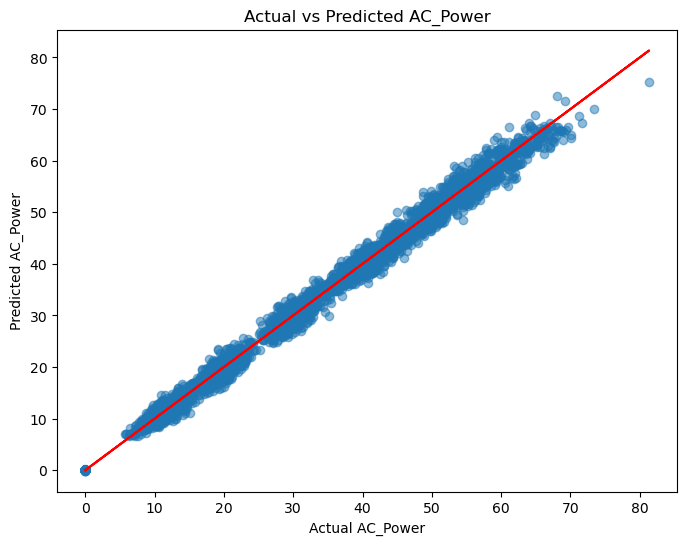

In [88]:
import matplotlib.pyplot as plt
%matplotlib inline
plt.figure(figsize=(8,6))
plt.scatter(y_test,y_pred_tuned_gb,alpha=0.5)
plt.xlabel("Actual AC_Power")
plt.ylabel("Predicted AC_Power")
plt.plot(y_test, y_test, color="red")
plt.title("Actual vs Predicted AC_Power")
plt.plot([y_test.min(), y_test.max()],[y_test.min(), y_test.max()],color="red",linestyle="--")
plt.show() 

#### The Actual vs Predicted plot shows that most predicted values are close to the actual values. This indicates that the Tuned Gradient Boosting model performs well in predicting AC power generation, with relatively small prediction errors.